# 1. The safety-car model

**Question:** on which lap is a safety car, VSC or red flag likely to start, at which circuit, and how long does it last?

This notebook walks through `src/sc_model.py`: the data it is fitted on, the model, how it does on seasons it has not seen, and what it says about Las Vegas 2026. It reads only the small tables in `data/` and `outputs/`, so it needs no F1 login. Run `python -m src.sc_events` and `python -m src.sc_model` first.

**What it finds** (with 20 of the 23 races of 2026 run):
- **The start is the dangerous part.** About one dry race in five has a neutralisation that starts on lap 1, and lap 2 is the next most likely lap. After that the chance is flat at just under 2% a lap: early, middle and late race don't differ.
- **Street circuits** run about 1.3 to 1.5 times the rate of permanent ones. Beyond that the data can't tell circuits apart: a circuit's own record moves its rate by a few per cent at most.
- **2026 has had about 2.3 times the usual number of VSCs** and the usual number of safety cars. The model carries that into the remaining 2026 races.
- **On three hold-out seasons** the model clearly beats "each circuit's own history" and only ties with "the same number for every race". It expected more safety cars than came in all three seasons.
- **Las Vegas 2026:** 87% chance of at least one neutralisation (79 to 93%), 54% chance of at least one safety car or red flag.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.simplefilter("ignore")
import numpy as np, pandas as pd
from IPython.display import Image
from src import sc_model as M
from src.data_loader import ROOT, load_config

cfg = load_config()
races, events = pd.read_csv(ROOT / "data" / "races.csv"), pd.read_csv(ROOT / "data" / "sc_events.csv")
every = M.at_risk(races, events, cfg)      # every race, wet ones included
laps = every[~every.wet]                   # the model's data: dry races only
print(f"{len(races)} races, {races.wet.sum()} wet -> {len(laps):,} at-risk laps in {laps.groupby(M.KEY).ngroups} dry races")
print("incidents by type:", laps.type.value_counts().to_dict(), "| by kind:", laps.kind[laps.kind != ""].value_counts().to_dict())
laps[laps.kind != ""][["year", "round", "circuit", "lap", "kind", "type", "span", "length"]].tail(6)

190 races, 21 wet -> 9,671 at-risk laps in 169 dry races
incidents by type: {'SC': 98, 'VSC': 95, 'RED': 20} | by kind: {'SC': 118, 'VSC': 95}


,year,round,circuit,lap,kind,type,span,length
10607,2026,17,Singapore,8,VSC,VSC,1.0,0.71
10637,2026,17,Singapore,39,VSC,VSC,1.0,1.14
10661,2026,18,Austin,2,VSC,VSC,0.0,0.22
10710,2026,18,Austin,51,VSC,VSC,2.0,1.85
10720,2026,19,Mexico City,7,VSC,VSC,1.0,1.59
10756,2026,19,Mexico City,44,SC,RED,2.0,NaN


## 1. From events to at-risk laps

The event table has one row per SC, VSC or red flag. Rows that belong together share an `episode`: a VSC that becomes an SC a lap later, or an SC, the red flag it turned into and the SC that led the restart. The model counts **incidents** (episodes), and names each after its worst row: VSC < SC < red flag.

A hazard is a conditional probability: the chance that an incident starts on this lap, *given that none is running*. So the laps an incident already covers are taken out of the table. What is left is one row per lap on which something could start, the **at-risk laps**. Each is one trial, and the lap an incident starts on is a trial that came up 1.

Only dry races are used. The 21 wet races run about 1.3 times the rate per lap (2.9 against 2.2 incidents per 100 laps), and the strategy optimiser is for dry races.

`span` is the number of laps the incident runs on after its first; `length` is its length in leader laps (blank when a red flag stopped the clock).

The table below is the whole model in raw form: incidents per 100 at-risk laps, by where in the race and by circuit type.

In [2]:
where = pd.Series(np.select([laps.lap == 1, laps.lap == 2], ["lap 1", "lap 2"], "laps 3+"), index=laps.index, name="where")
t = laps.groupby([where, laps.street.map({True: "street", False: "permanent"}).rename("circuit")]).agg(
    at_risk_laps=("lap", "size"), sc_kind=("kind", lambda k: (k == "SC").sum()), vsc=("kind", lambda k: (k == "VSC").sum()))
t["sc_per_100_laps"], t["vsc_per_100_laps"] = (100 * t.sc_kind / t.at_risk_laps).round(2), (100 * t.vsc / t.at_risk_laps).round(2)
t

at_risk_laps  sc_kind  vsc  sc_per_100_laps  \
where   circuit                                                  
lap 1   permanent           128       26    3            20.31   
        street               41        8    0            19.51   
lap 2   permanent            99        5    5             5.05   
        street               33        0    2             0.00   
laps 3+ permanent          7116       53   57             0.74   
        street             2254       26   28             1.15   

                   vsc_per_100_laps  
where   circuit                      
lap 1   permanent              2.34  
        street                 0.00  
lap 2   permanent              5.05  
        street                 6.06  
laps 3+ permanent              0.80  
        street                 1.24

Three things to read off it:
- **Lap 1** is about 25 times as likely to start a safety car as a later lap, and it is almost never a VSC (3 of 37): a first-lap crash leaves cars and debris on the track.
- **Lap 2** is high too. The lap is the leader's (decision D-016): he is already on lap 2 when a crash at the back of the field on lap 1 gets its safety car, and the field is still bunched.
- **From lap 3** the rate is flat, and street circuits run about 1.5 times the permanent ones for both kinds.

## 2. Two hazards, one recipe

Safety cars and VSCs behave differently, so each gets its own hazard:
- **SC-kind:** a safety car or a red flag. Red flags are counted here because 19 of the 26 red flags in the data began as an SC or VSC. A red flag is how a bad incident escalates, not a separate kind of event. (PRD open question 2.)
- **VSC:** an incident dealt with by the VSC alone.

Each hazard is a logistic regression on the at-risk laps, pooled over all circuits, with three yes / no features:

$$\text{logit}\,P(\text{starts on this lap}) = b_0 + b_1\,\text{lap 1} + b_2\,\text{lap 2} + b_3\,\text{street}$$

In [3]:
model = M.fit(laps, cfg)
M.coefficients(model).round(3)

coef     se  odds_x
SC  baseline -4.835  0.128   0.008
    lap1      3.390  0.223  29.680
    lap2      1.530  0.470   4.620
    street    0.257  0.211   1.294
VSC baseline -4.798  0.129   0.008
    lap1      0.680  0.593   1.973
    lap2      1.809  0.404   6.102
    street    0.378  0.222   1.459

**How to read it.** `odds_x` is what the feature multiplies the odds by. At probabilities this small, odds and probability are almost the same number, so "street: 1.29" means a street circuit has about 1.3 times the safety-car rate per lap.

**`se` is the honest part.** The street effect on safety cars is 0.26 ± 0.21 in log-odds: anywhere from no effect to almost double. With 118 SC-kind incidents in nine seasons this is as sharp as it gets. The model does not hide this: section 5 draws the coefficients from these standard errors and carries the spread into every simulated race.

**What is not in the model**, and why: the PRD asked for an early / mid / late bucket, and its open question 3 asked whether "laps since the last safety car" matters. Both were tried, and section 4 shows that neither helps on seasons the model has not seen.

## 3. What a circuit's own record adds: shrinkage

Baku has had an incident in 8 of its 8 dry races, Budapest in 3 of 7. A real difference, or luck? With five to ten races a circuit, mostly luck. So each circuit gets a multiplier on the pooled rate that is pulled towards 1:

$$\text{multiplier} = \frac{\text{observed} + s}{\text{expected} + s}$$

- *observed*: the circuit's incidents. *expected*: what the pooled model gives for the same laps.
- *s*, the **strength**, is how many incidents' worth of "it is just an average circuit" is mixed in. At 0 the multiplier is the raw ratio; when *s* is large it is 1.
- It is the mean of a Gamma posterior (a Gamma(*s*, *s*) prior on the multiplier, a Poisson count), so it also has a spread: Gamma(*s* + observed, *s* + expected). That spread is the circuit's part of the uncertainty band.

*s* is not picked by hand. It is the value that makes the spread of the circuits' counts most likely. If circuits differ by much more than chance allows, *s* comes out small. If they differ by no more than chance, it runs to its upper limit (100 in `config.yaml`), which pins every multiplier within about 10% of 1.

In [4]:
def record(kind, group):
    k = model[kind]
    t = pd.DataFrame(k[group], index=["observed", "expected"]).T
    return t.assign(raw_ratio=t.observed / t.expected, multiplier=[M.multiplier(r, k[group + "_strength"]) for r in k[group].values()]).round(2)

for kind in M.KINDS:
    print(f"{kind}: circuit strength {model[kind]['circuit_strength']:.0f}, season strength {model[kind]['season_strength']:.0f}")
c = record("SC", "circuit").sort_values("multiplier")
pd.concat([c.head(4), c.loc[["Las Vegas"]], c.tail(4)])

SC: circuit strength 30, season strength 100
VSC: circuit strength 100, season strength 6


,observed,expected,raw_ratio,multiplier
Budapest,0.0,5.29,0.00,0.85
Austin,2.0,5.10,0.39,0.91
Monaco,3.0,6.10,0.49,0.91
Spielberg,4.0,7.46,0.54,0.91
Las Vegas,2.0,2.17,0.92,0.99
Melbourne,7.0,4.81,1.45,1.06
Jeddah,6.0,3.58,1.68,1.07
Sao Paulo,7.0,4.32,1.62,1.08
Silverstone,10.0,4.65,2.15,1.15


For safety cars the strength is 30: a circuit needs about 30 incidents before its own record counts as much as the pooled model, and no circuit has more than 10. So the multipliers run only from 0.85 (Budapest: no safety car in seven dry races, where 5.3 were expected) to 1.15 (Silverstone: 10 where 4.7 were expected). For VSCs the strength sits at the limit: the circuits' VSC counts differ by *less* than chance alone would give.

**Las Vegas is a generic street circuit as far as the data can tell** (multiplier 0.99). Three races can't say more. This is the PRD's "rare events" risk in numbers.

The same recipe is then applied to **seasons**, on what the circuits left unexplained:

In [5]:
pd.concat({kind: record(kind, "season") for kind in M.KINDS}, axis=1)

SC                                    VSC                     \
     observed expected raw_ratio multiplier observed expected raw_ratio   
2018     14.0    13.72      1.02       1.00     13.0    11.11      1.17   
2019     12.0    13.95      0.86       0.98      6.0    11.45      0.52   
2020     16.0     9.01      1.78       1.06      4.0     6.73      0.59   
2021     13.0    11.72      1.11       1.01     11.0     9.44      1.17   
2022     15.0    12.23      1.23       1.02     13.0     9.88      1.32   
2023     16.0    13.88      1.15       1.02      7.0    11.24      0.62   
2024     10.0    14.77      0.68       0.96      6.0    12.18      0.49   
2025     12.0    14.88      0.81       0.97     11.0    12.35      0.89   
2026     10.0    12.63      0.79       0.98     24.0    10.55      2.28   

                 
     multiplier  
2018       1.11  
2019       0.69  
2020       0.79  
2021       1.10  
2022       1.19  
2023       0.76  
2024       0.67  
2025       0.93  
2026       1.80

- **Safety cars:** the seasons differ by no more than chance (strength at the limit), so every season's multiplier is close to 1. Note the last three raw ratios, though: 0.68, 0.81, 0.79. Section 7 comes back to this.
- **VSCs:** the seasons really do differ (strength 6). 2026 has 24 VSC incidents where 10.5 were expected, and after shrinkage its multiplier is 1.8.

Why 2026? It is the first year of new cars and power units, and a car that stops on track with a failure is the classic VSC. That is a guess, not something this data tests. The model doesn't need the reason. It needs to know whether a season's record so far says anything about its next race, and that can be tested.

## 4. Does it hold up on seasons it has not seen?

Three folds: 2024 predicted from 2018-2023, 2025 from 2018-2024, 2026 from 2018-2025. Inside a test season the races are predicted in order, and each race joins the season's record only after it has been predicted. Nothing from the future gets in.

Two scores, both "lower is better":
- **Log loss per lap:** for every at-risk lap, minus the log of the probability the model gave to what happened (nothing, an SC-kind incident, a VSC). It uses every lap, so it is the sharper tool, and it is the one used to choose between versions of the model.
- **Brier score per race:** (P(at least one) − what happened)², the PRD's measure.

In [6]:
pd.read_csv(ROOT / "outputs" / "sc_variants.csv")

,variant,logloss_per_100_laps,brier_any,brier_sc
0,PRD spec,11.4532,0.1851,0.2747
1,+ lap 2,11.2669,0.1847,0.2749
2,no race phase,11.2341,0.1846,0.2749
3,street after lap 2 only,11.2801,0.1846,0.2752
4,+ after a restart,11.2637,0.1864,0.2736
5,+ race length,11.2416,0.1872,0.2730
6,"chosen, no circuit multiplier",11.2261,0.1841,0.2753
7,"chosen, no season multiplier",11.2875,0.1879,0.2760
8,"chosen, no multipliers",11.2803,0.1874,0.2766


- **Lap 2** is the one clear gain over the PRD's spec (11.45 → 11.27).
- **The race-phase buckets** make it slightly worse, so they are out. So is **"after a restart"** (PRD open question 3: no, clustered incidents are already merged into one incident by the event table) and **race length**.
- **"Street after lap 2 only"** is a lesson. Looking at all the data, the street effect seemed to be absent on laps 1 and 2, and a model with that idea fits the data better. On the hold-out it is worse than the plain street flag. An idea found by staring at the data has to pass a test on data it has not seen.
- **The circuit multiplier** buys nothing (11.226 without, 11.234 with). It stays because the PRD asks for it, it costs nothing, and its posterior is what makes the uncertainty band circuit-specific.
- **The season multiplier** is a small gain (11.288 → 11.234).

One caveat: the features were chosen on these same three seasons, so the chosen model's score flatters it a little.

Now the PRD's test: the chosen model against two baselines. `hist` = the share of that circuit's earlier races that had an incident; `pool` = the share of all earlier races. `any` = at least one neutralisation; `sc` = at least one safety car or red flag. `lead_` is how far the model is ahead of a baseline, with its standard error.

In [7]:
v, lap_pred = M.validate(laps, cfg)
pd.concat({what: M.brier(v, what) for what in ("any", "sc")}).round(4)

races   model    hist    pool  lead_hist  se_hist  lead_pool  \
any 2024     21  0.2729  0.3360  0.2846        NaN      NaN        NaN   
    2025     21  0.1939  0.2284  0.2047        NaN      NaN        NaN   
    2026     18  0.0710  0.1125  0.0702        NaN      NaN        NaN   
    all      60  0.1846  0.2313  0.1923     0.0467   0.0238     0.0076   
sc  2024     21  0.2888  0.4098  0.2863        NaN      NaN        NaN   
    2025     21  0.2549  0.2556  0.2581        NaN      NaN        NaN   
    2026     18  0.2820  0.2465  0.2469        NaN      NaN        NaN   
    all      60  0.2749  0.3068  0.2646     0.0320   0.0267    -0.0103   

          se_pool  
any 2024      NaN  
    2025      NaN  
    2026      NaN  
    all    0.0084  
sc  2024      NaN  
    2025      NaN  
    2026      NaN  
    all    0.0117

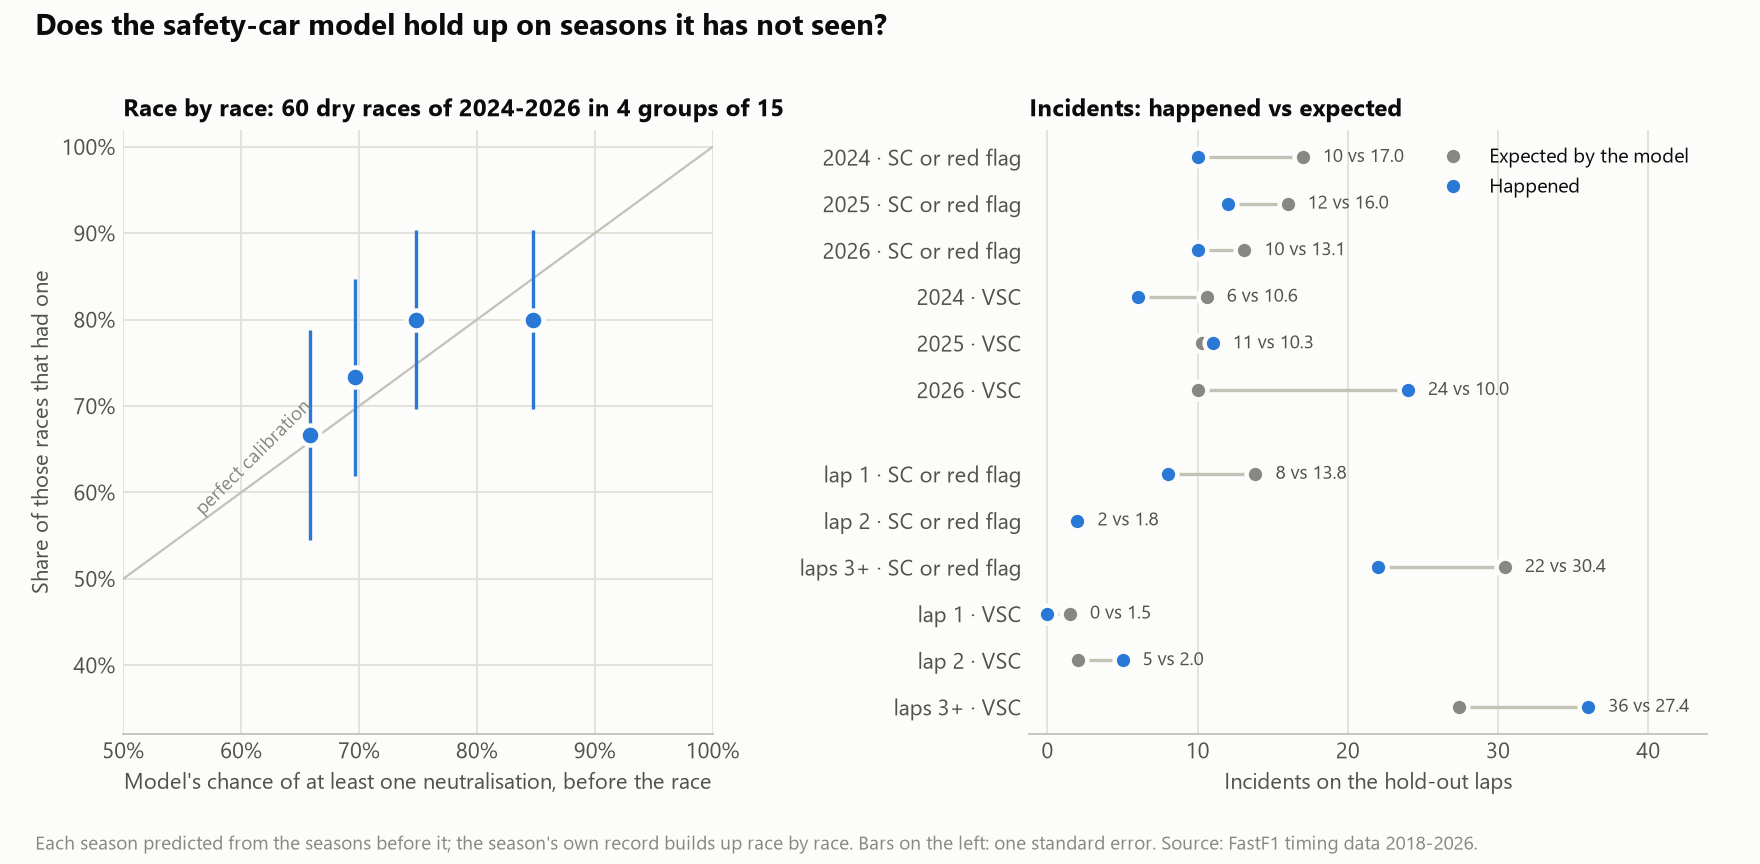

In [8]:
Image(filename=str(ROOT / "outputs" / "chart2_sc_calibration.png"), width=950)

**Reading it honestly:**
1. **Against circuit history the model wins clearly:** 0.185 against 0.231, a lead of 0.047 ± 0.024. This is the PRD's success criterion. A circuit's own record is a poor forecaster, because five to eight races are mostly noise.
2. **Against "the same number for every race" it is a tie:** a lead of 0.008 ± 0.008 for any neutralisation, and the model is behind by 0.010 ± 0.012 for safety cars. Knowing the circuit tells you very little about *whether* there will be a safety car.
3. **Calibration** (left panel): the four groups sit within one standard error of the diagonal. When the model says 85%, about 80% of races had one.
4. **The miss** (right panel): the model expected 46 SC-kind incidents over the three seasons and 32 came. It was short in every season, both on lap 1 (8 against 13.8) and on the later laps (22 against 30.4). And 2026's VSCs: 24 against 10. The season multiplier only learns as the season goes.

So what is the model for, if it can't beat a constant at picking which races get a safety car? The optimiser doesn't need that. It needs the **shape**: a spike on laps 1 and 2 and a flat rate after, how the rate splits into safety cars and VSCs, how long each lasts, and an honest spread around all of it. A constant gives none of those.

The races the model was most and least sure about:

In [9]:
cols = ["year", "round", "circuit", "laps", "p_any", "hist_any", "pool_any", "any", "n_sc", "n_vsc"]
pd.concat([v.sort_values("p_any")[cols].head(5), v.sort_values("p_any")[cols].tail(5)]).round(2)

,year,round,circuit,laps,p_any,hist_any,pool_any,any,n_sc,n_vsc
11,2024,14,Spa-Francorchamps,44,0.61,0.80,0.77,False,0,0
51,2026,10,Spa-Francorchamps,44,0.63,0.67,0.74,True,1,2
16,2024,19,Austin,56,0.65,0.60,0.77,True,1,0
22,2025,3,Suzuka,53,0.65,0.75,0.74,False,0,0
36,2025,19,Austin,56,0.65,0.67,0.74,True,0,1
2,2024,3,Melbourne,58,0.87,0.75,0.77,True,0,2
29,2025,10,Montreal,70,0.87,0.75,0.74,True,1,0
47,2026,6,Monaco,78,0.87,0.80,0.74,True,1,0
27,2025,8,Monaco,78,0.89,0.75,0.74,True,0,1
7,2024,8,Monaco,78,0.90,0.67,0.77,True,1,0


The spread of `p_any` (0.61 to 0.90) comes from two things only: street or permanent, and the number of laps. Monaco is at the top because it has 78 of them.

## 5. Las Vegas 2026

The model fitted on every dry race so far, asked about a 50-lap race at Las Vegas, with and without 2026's record:

In [10]:
rng = np.random.default_rng(cfg["sc_model"]["seed"])
m = cfg["sc_model"]
for year, label in ((None, "no season effect"), (2026, "with 2026's record")):
    h = M.hazard(model, "Las Vegas", 50, year)
    lo, hi = np.percentile(M.p_at_least_one(M.hazard(model, "Las Vegas", 50, year, m["draws"], rng)), m["band"])
    print(f"{label:>19}: P(at least one) {M.p_at_least_one(h):.0%} ({lo:.0%} to {hi:.0%}) | P(SC or red flag) {M.p_at_least_one(h[:1]):.0%} | "
          f"P(VSC) {M.p_at_least_one(h[1:]):.0%} | expected {h[0].sum():.2f} SC-kind + {h[1].sum():.2f} VSC incidents")
M.by_lap(model, laps, "Las Vegas", 50, 2026, rng).round(3).head(4)

   no season effect: P(at least one) 77% (66% to 87%) | P(SC or red flag) 55% | P(VSC) 49% | expected 0.76 SC-kind + 0.66 VSC incidents
 with 2026's record: P(at least one) 87% (79% to 93%) | P(SC or red flag) 54% | P(VSC) 70% | expected 0.75 SC-kind + 1.19 VSC incidents


,lap,p,p_lo,p_hi,p_sc,p_vsc,cum,cum_lo,cum_hi,avg,avg_cum
0,1,0.269,0.195,0.373,0.227,0.042,0.269,0.195,0.373,0.218,0.218
1,2,0.167,0.110,0.264,0.044,0.123,0.391,0.308,0.517,0.091,0.289
2,3,0.031,0.024,0.040,0.010,0.021,0.410,0.326,0.534,0.018,0.301
3,4,0.031,0.024,0.040,0.010,0.021,0.428,0.344,0.551,0.017,0.313


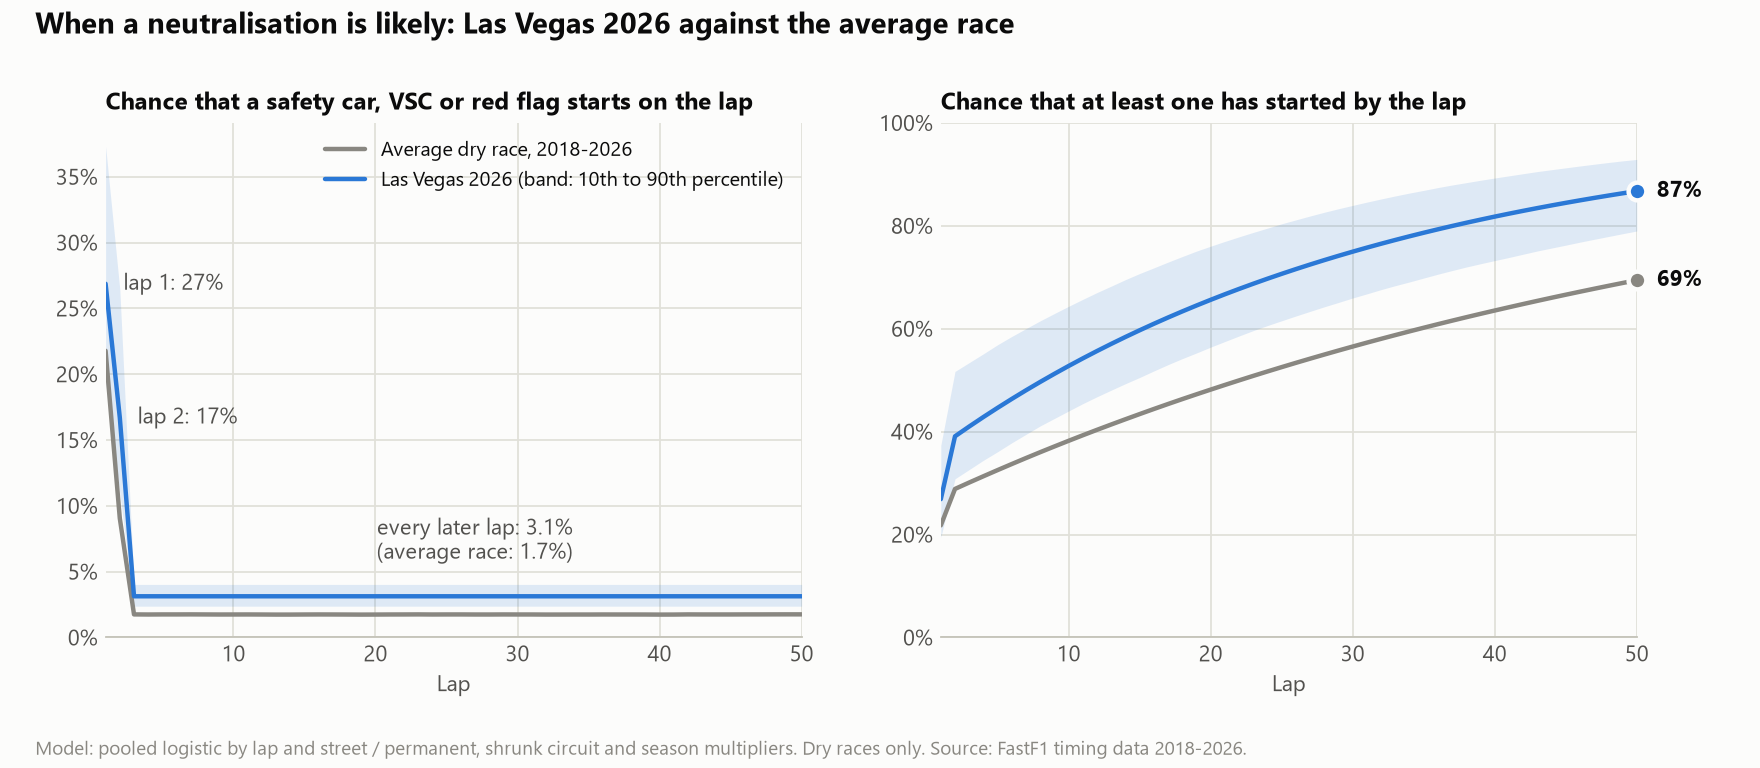

In [11]:
Image(filename=str(ROOT / "outputs" / "chart1_sc_by_lap.png"), width=950)

**Where the band comes from.** The model is unsure of three things: the logistic's coefficients (their standard errors), the circuit multiplier and the season multiplier (their Gamma posteriors). `hazard(..., draws=4000)` draws all three 4,000 times; the band is the 10th to 90th percentile of the result. For Las Vegas the coefficients and the 2026 VSC multiplier do most of the work, since the circuit multiplier is pinned near 1.

**Las Vegas against the average race:** higher because it is a street circuit and because of 2026's VSC rate. Its own record (four incidents in three races) barely moves it.

## 6. Sampling races for the optimiser

`sample()` is what the Monte Carlo will call. It walks through the laps of *n* races at once. On each lap a race that has nothing running draws against the two hazards; if an incident starts, its type and length are copied from a randomly chosen real incident of that kind (so one SC-kind incident in six is a red flag, as in the data), and the race is not at risk again until that incident's last lap.

Each simulated race first draws **its own** hazards from the model's uncertainty. So the 10,000 races don't all assume the model is right: some come from a world with a higher VSC rate, some from a lower one. This is how the uncertainty in the band reaches the strategy ranking.

In [12]:
s = M.sample(model, "Las Vegas", 50, rng, n=10_000, year=2026)
print(s.head(8).to_string(index=False))
per_race = s.groupby("sim").size().reindex(range(10_000), fill_value=0)
print("\nincidents in a race (share of races):", per_race.value_counts(normalize=True).sort_index().round(3).to_dict())
print("type of an incident:", s.type.value_counts(normalize=True).round(3).to_dict())
print(f"races with a red flag: {s[s.type == 'RED'].sim.nunique() / 10_000:.1%}")
s.groupby("type").laps.describe()[["count", "25%", "50%", "75%"]].round(2)

 sim  lap type  end_lap  laps
   0    2  VSC        3  1.84
   0   46  RED       47   NaN
   1    5  VSC        6  0.59
   1   24  VSC       24  0.50
   1   25  VSC       26  0.59
   2    1  VSC        2  0.92
   2    3  RED        3   NaN
   2   32  VSC       33  0.56

incidents in a race (share of races): {0: 0.133, 1: 0.304, 2: 0.293, 3: 0.177, 4: 0.067, 5: 0.021, 6: 0.004, 7: 0.001, 8: 0.0}
type of an incident: {'VSC': 0.614, 'SC': 0.32, 'RED': 0.067}
races with a red flag: 11.5%


,count,25%,50%,75%
type,,,,
RED,0.0,NaN,NaN,NaN
SC,5848.0,3.14,3.68,4.72
VSC,11235.0,0.68,0.98,1.59


## 7. Where the model is weakest

- **Safety cars have been rarer since 2024.** The last three seasons had about a third fewer SC-kind incidents than 2018-2023 would predict (32 against 46 on the hold-out). Taken season by season this is within chance, so the model does not react, and it may be expecting too many at Las Vegas: 0.75 SC-kind incidents, against about 0.6 if the recent level holds. The optimiser's results will be shown at both levels (M4).
- **The 2026 VSC rate is assumed to last** for the three races left. It is the model's largest single adjustment and rests on 20 races.
- **Risk per lap, or per race?** Fitted on all the data, the safety-car rate per lap falls with the number of laps (a coefficient of −1.6 ± 0.7, where −1 would mean "the risk is per race, not per lap"). If so, the model gives short-lap circuits like Monaco too many safety cars and long-lap ones (Spa, and slightly Las Vegas with 50 laps) too few. It did not help on the hold-out, so it is not in the model.
- **Whole laps, on the leader's clock.** A safety car that comes out just after the leader has crossed the line is "next lap" for him and "this lap" for everyone else.
- **Lengths are pooled** over all circuits and seasons, and a red flag has no length here (the stoppage stops the lap clock).
- **213 incidents** is all there is. Every number above has a wide band, and the band is part of the answer.